# Geometrie und Trigonometrie

## 04 - Flächeninhalte und Skalierung (Das Pizza-Prinzip)

Bisher haben wir gelernt, dass **ähnliche Figuren** gleiche Winkel haben und ihre Seitenverhältnisse konstant sind. Wenn wir eine Figur vergrößern ("zoomen"), multiplizieren wir alle Längen mit einem Faktor $k$.

Aber was passiert dabei mit der **Fläche**?
Viele Menschen denken intuitiv: "Doppelte Breite = Doppelte Fläche".
**Das ist falsch.** In diesem Notebook werden wir sehen, warum Flächen viel schneller wachsen als Längen.

**Lernziele:**
- Du verstehst den Unterschied zwischen linearer Skalierung (Länge) und quadratischer Skalierung (Fläche).
- Du kannst den neuen Flächeninhalt berechnen, wenn der Vergrößerungsfaktor $k$ bekannt ist.
- Du kannst dieses Wissen auf Alltagsprobleme (Preise, Kartenmaßstäbe) anwenden.

### 1. Das Pizza-Problem

Stellen wir uns vor, wir sind in einer Pizzeria und wollen Pizza bestellen.
- Eine **kleine Pizza** (20cm Durchmesser) kostet **$5\text{€}$**.
- Eine **große Pizza** (40 cm Durchmesser) kostet **$15\text{€}$**.

Welches Angebot ist besser?
Intuitiv denken viele: "Die große ist doppelt so groß ($40 * 2 = 20$), kostet aber dreimal so viel, daher ist eine kleine Pizza ein besseres Angebot ($5 * 2 = 10 < 15$)

Mathematisch ist das jedoch falsch. Wenn wir den Durchmesser verdoppeln ($k = 2$), vierfacht sich die Fläche. Aber warum ist das so?

### 2. Mathematische Herleitung

Betrachten wir ein Rechteck mit den Seitenlängen $a$ und $b$.
Der Flächeninhalt ist $A = a \cdot b$.

Nun vergrößern wir das Rechteck um den **Skalierungsfaktor** $k$.
Die neuen Seitenlängen sind $a' = k \cdot a$ und $b' = k \cdot b$.

Wie groß ist die neue Fläche $A'$?

$$
\begin{aligned}
A' &= a' \cdot b' \\
A' &= (k \cdot a) \cdot (k \cdot b) \\
A' &= k \cdot k \cdot a \cdot b \\
A' &= k^2 \cdot (a \cdot b) \\
A' &= k^2 \cdot A \\
\end{aligned}
$$

**Gesetz der Flächenskalierung:**
Wird eine Figur um den Faktor $k$ vergrößert, wächst ihr Flächeninhalt um den Faktor $k^2$.
- Doppelte Länge ($k=2$) $\rightarrow$ $2^2 = 4$-fache Fläche
- Dreifach Länge ($k=3$) $\rightarrow$ $3^2 = 9$-fache Fläche
- Halbe Länge ($k=0.5$) $\rightarrow$ $2^2 = 0.25$-fache Fläche (Ein Viertel)

In [1]:
"""Settings für den statischen Plot der Flächenskalierung"""
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Settings für den Plot
Square_Settings = {
    "base_size": 1,
    "scale_factor": 2,
    "color_base": "blue",
    "color_scaled": "orange",
    "alpha": 0.5,
    "figsize": (8, 6),
}

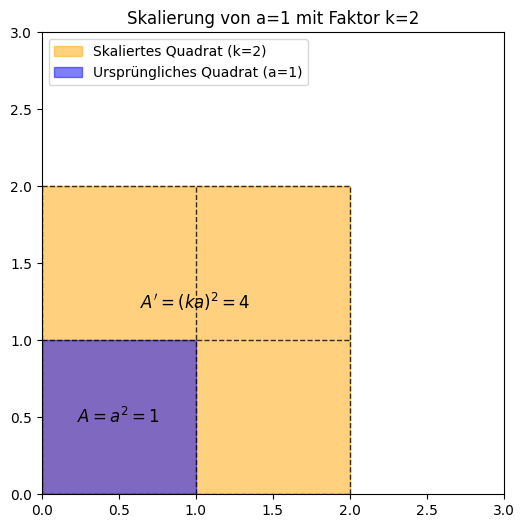

In [2]:
def plot_scaled_squares(ax, cfg):
    a = cfg["base_size"]
    k = cfg["scale_factor"]

    # Limits und Setup
    ax.set_xlim(0, k*a +1)
    ax.set_ylim(0, k*a +1)
    ax.set_aspect('equal')
    ax.set_title(f"Skalierung von a={a} mit Faktor k={k}")

    # 1. Großes Quadrat
    rect_scaled = patches.Rectangle((0, 0), k*a, k*a, facecolor=cfg["color_scaled"], edgecolor=cfg["color_scaled"], 
                                    alpha=cfg["alpha"], label=f"Skaliertes Quadrat (k={k})")
    ax.add_patch(rect_scaled)

    # 2. Kleines Quadrat
    rect_base = patches.Rectangle((0,0), a, a, facecolor=cfg["color_base"], edgecolor=cfg["color_base"],
                                    alpha=cfg["alpha"], label=f"Ursprüngliches Quadrat (a={a})")
    ax.add_patch(rect_base)

    # 3. Hilfslinien und Beschriftungen
    for i in range(k + 1):
        # Vertikale Linien
        ax.plot([i*a, i*a], [0, k*a], 'k--', lw=1, alpha=0.8)
        # Horizontale Linien
        ax.plot([0, k*a], [i*a, i*a], 'k--', lw=1, alpha=0.8)

    # Text-Annotations
    ax.text(a/2, a/2, f"$A = a^2={a**2}$", color='black', fontsize=12, ha='center', va='center')
    ax.text(k*a/2, k*a/2 + 0.25, f"$A' = (ka)^2={ (k*a)**2 }$", color='black', fontsize=12, ha='center', va='center')

    ax.legend(loc='upper left')

fig, ax = plt.subplots(figsize=Square_Settings["figsize"])
plot_scaled_squares(ax, Square_Settings)
plt.show()

### 3. Verallgemeinerung

Das Gesetz $A' = k^2 \cdot A$ gilt nicht nur für Quadrate, sondern für alle 2-dimensionalen geometrischen Figuren, solange sie **ähnlich** sind.

**Beispiel Kreis:**
$$A = r^2 \cdot \pi$$
Verdoppeln wir den Radius ($r' = 2r$), dann gilt:
$$A' = (2r)^2 \cdot \pi = 4r^2 \cdot \pi = 4 \cdot A$$

**Beispiel Landkarten:**
Eine Karte hat den Maßstab $1:50.000$.
Das bedeutet $1$ cm auf der Karte sind $50.000$ cm ($500$ m) in der Realität.
Der Längen-Faktor ist also $k = 50.000$.

Wie verhält es sich mit der Fläche?
$1 \text{ cm}^2$ auf der Karte entspricht in der Realität:
$$1 \text{ cm}^2 \cdot (50.000)^2 = 1 \cdot 2.500.000.000 \text{ cm}^2 = 250.000 \text{ m}^2 = 25 \text{ Hektar}$$
Der Flächenmaßstab ist also $1 : k^2$.


### 4. Interaktive Visualisierung: Längen- vs. Flächenwachstum

In der folgenden Animation sehen wir uns an, wie sich die Fläche verändert, wenn wir den Skalierungsfaktor $k$ kontinuierlich von 1 bis 3 erhöhen.
Wir stellen dies in einem Graphen dar. Während die Seitenlänge linear wächst (eine Gerade), wächst die Fläche quadratisch (eine Parabel).

In [3]:
# Settings für Animation
Animation_Settings = {
    "k_min": 1.0,
    "k_max": 4.0,
    "frames": 60,
    "interval": 25,
    "color_line": "blue",
    "color_area": "red"
}

In [4]:
import numpy as np
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

def create_scaling_animation(cfg):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle("Lineare vs. Quadratisches Wachstum", fontsize=16)

    # --- Linker Plot: Die Geometrie ---
    ax1.set_xlim(0, cfg["k_max"] + 1)
    ax1.set_ylim(0, cfg["k_max"] + 1)
    ax1.set_aspect('equal')
    ax1.grid(True, alpha=0.3)
    ax1.set_title("Geometrische Figur (Quadrat)")

    # Das Quadrat
    rect = patches.Rectangle((0,0), 1, 1, ec='black', fc='skyblue', alpha=0.7)
    ax1.add_patch(rect)

    # Labels für Seite und Fläche
    txt_side = ax1.text(0.5, 0.1, "Seite = 1.0", ha='center', va='center', fontsize=12)
    txt_area = ax1.text(0.5, 1.05, "Fläche = 1.0", ha='center', va='center', fontsize=12)

    # --- Rechter Plot: Der Graph ---
    ax2.set_xlim(cfg["k_min"], cfg["k_max"])
    ax2.set_ylim(0, cfg["k_max"]**2 + 1)
    ax2.set_xlabel("Skalierungsfaktor k")
    ax2.set_ylabel("Wert")
    ax2.set_title("Wachstums-Kurven")
    ax2.grid(True, alpha=0.3)
    
    # Daten für die Kurven
    k_values = np.linspace(cfg["k_min"], cfg["k_max"], 100)
    len_values = k_values      # Lineares Wachstum
    area_values = k_values**2  # Quadratisches Wachstum
    
    # Statische Kurven (im Hintergrund grau angedeutet)
    ax2.plot(k_values, len_values, 'b--', alpha=0.3, label='Seitenlänge (k)')
    ax2.plot(k_values, area_values, 'r--', alpha=0.3, label='Fläche (k²)')
    
    # Bewegliche Punkte
    dot_len, = ax2.plot([], [], 'bo', markersize=8)
    dot_area, = ax2.plot([], [], 'ro', markersize=8)
    
    ax2.legend()
    
    def init():
        return rect, txt_side, txt_area, dot_len, dot_area
        
    def update(frame):
        # Fortschritt 0..1
        progress = frame / cfg["frames"]
        current_k = cfg["k_min"] + (cfg["k_max"] - cfg["k_min"]) * progress
        current_area = current_k**2
        
        # 1. Update Geometrie
        rect.set_width(current_k)
        rect.set_height(current_k)
        
        # Text positionieren
        txt_side.set_position((current_k/2 + 0.2, 0.2))
        txt_side.set_text(f"Seite = {current_k:.2f}")
        
        txt_area.set_position((current_k/2, current_k/2))
        txt_area.set_text(f"A = {current_area:.2f}")
        
        # 2. Update Graph
        dot_len.set_data([current_k], [current_k])
        dot_area.set_data([current_k], [current_area])
        
        return rect, txt_side, txt_area, dot_len, dot_area

    anim = FuncAnimation(fig, update, frames=cfg["frames"], init_func=init, blit=True, interval=cfg["interval"])
    plt.close()
    return anim

anim = create_scaling_animation(Animation_Settings)
HTML(anim.to_jshtml())


### Verständnis-Check

**Aufgabe 1: Pizza-Finale**
Zurück zu unserem Beispiel vom Anfang:
- Pizza A: 20 cm Durchmesser, 5 €
- Pizza B: 40 cm Durchmesser, 15 €
Berechne den Skalierungsfaktor $k$ und den Flächenfaktor. Wie viel mal mehr Pizza bekommst du bei B im Vergleich zu A? Ist der Preis von 15 € gerechtfertigt?

**Aufgabe 2: Grundstückspreise**
Ein quadratisches Grundstück hat eine Seitenlänge von 30 Metern und kostet 90.000 €.
Ein Nachbargrundstück ist ebenfalls quadratisch, hat aber eine Seitenlänge von 60 Metern.
Wenn der Quadratmeterpreis gleich bleibt, wie viel müsste das große Grundstück kosten?

**Aufgabe 3: Der Fernseher**
Du wechselst von einem 30-Zoll Bildschirm auf einen 60-Zoll Bildschirm (die Diagonale verdoppelt sich).
Wie verändert sich die Bildfläche?

### Lösungen

**Lösung 1:**
- Skalierungsfaktor $k = \frac{40}{20} = 2$.
- Flächenfaktor $k^2 = 2^2 = 4$.
- Die Pizza B hat die **4-fache Fläche** (also 4-mal so viel Belag und Teig) wie Pizza A.
- Preisvergleich: $4 \times 5 € = 20 €$.
- Da Pizza B nur 15 € kostet, ist sie das deutlich bessere Angebot (mehr Pizza pro Euro).

**Lösung 2:**
- Seitenlänge verdoppelt sich ($30 \text{m} \rightarrow 60 \text{m}$), also $k=2$.
- Die Fläche vervierfacht sich ($k^2 = 4$).
- Preis: $90.000 € \cdot 4 = 360.000 €$.

**Lösung 3:**
- Die Angabe "Zoll" bei Bildschirmen bezieht sich auf die Diagonale (eine Länge).
- Verdopplung der Diagonale ($k=2$) bedeutet auch hier eine **Vervierfachung** der Bildfläche ($k^2=4$).

---

### Glossar (Deutsch - Englisch)

- **Flächeninhalt:** Area
- **Skalierung:** Scaling
- **Skalierungsfaktor:** Scale factor ($k$)
- **Maßstab:** Scale (on a map)
- **Quadratisch:** Quadratic / Square
- **Verhältnis:** Ratio
- **Ähnlich:** Similar
- **Umfang:** Perimeter (wächst linear mit $k$)